In [ ]:
# 1. Mount Google Drive
from google.colab import drive
import os
from pathlib import Path

drive.mount('/content/drive')

# 2. Check if MyDrive is accessible
my_drive = Path('/content/drive/MyDrive')
if not my_drive.exists():
    print("❌ Google Drive is not mounted properly! Please click the link above to grant access.")
else:
    print("✅ Google Drive is mounted successfully!")

# 3. Auto-search for where vfn_1_0 or Images folder actually is in Drive
print("\nSearching for your dataset folder in Drive...")
found_paths = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    # Don't look inside trash or hidden folders
    if '.Trash' in root or '.shortcut-targets-by-id' in root:
        continue
    if 'vfn_1_0' in dirs or (root.endswith('vfn_1_0') and 'Images' in dirs):
        found_paths.append(root if root.endswith('vfn_1_0') else os.path.join(root, 'vfn_1_0'))
    # Limit search depth so it doesn't take forever
    if root.count(os.sep) - '/content/drive/MyDrive'.count(os.sep) > 3:
        continue

if found_paths:
    print(f"🎉 FOUND your dataset at: {found_paths[0]}")
    print(f"👉 Set: DATA_DIR = Path('{found_paths[0]}')")
else:
    print("⚠️ Could not automatically find 'vfn_1_0'. Here are the top-level folders in your Drive:")
    print([p.name for p in my_drive.iterdir() if p.is_dir() and not p.name.startswith('.')])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive is mounted successfully!

Searching for your dataset folder in Drive...
🎉 FOUND your dataset at: /content/drive/MyDrive/vfn_1_0
👉 Set: DATA_DIR = Path('/content/drive/MyDrive/vfn_1_0')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Scanning from: /content/drive/MyDrive/vfn_1_0/Images
-> Successfully found 7196 images across the 28 folders!
Processing images (using 8 parallel threads for Colab)...
✅ Saved image metrics to: /content/drive/MyDrive/EDA_Outputs/pure_eda_images.csv


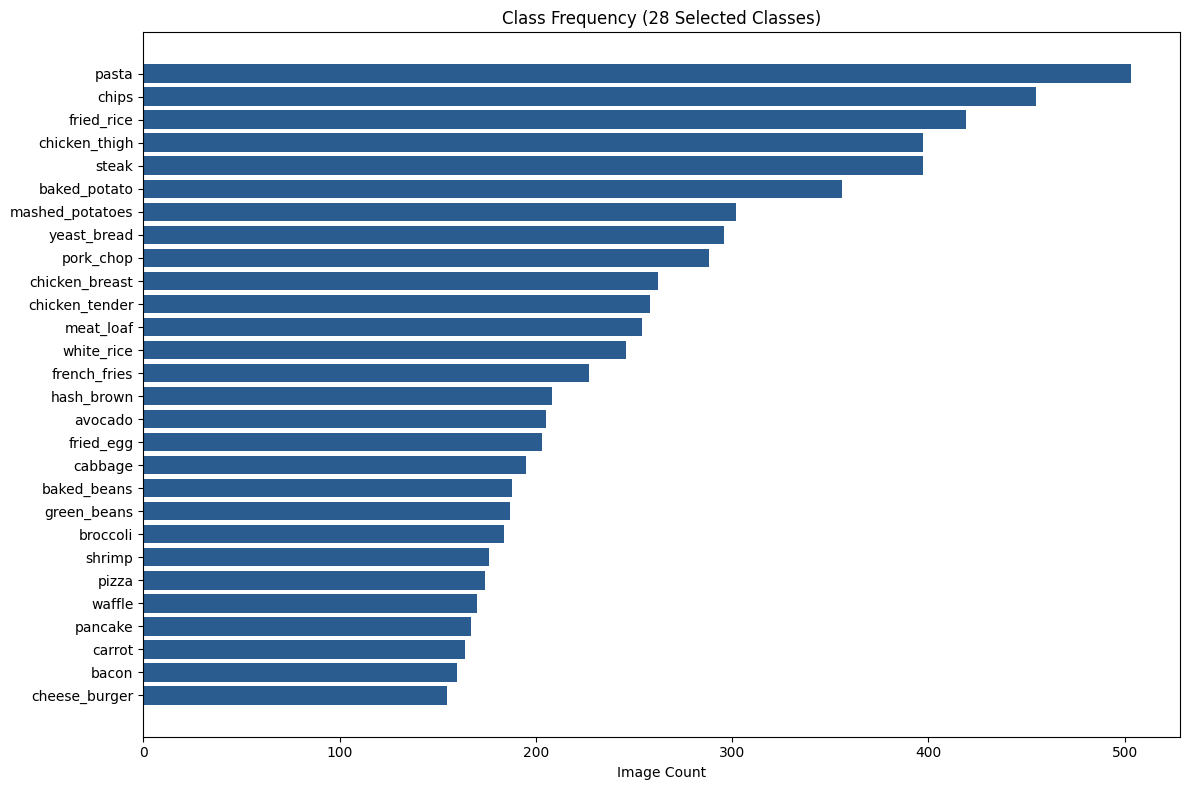

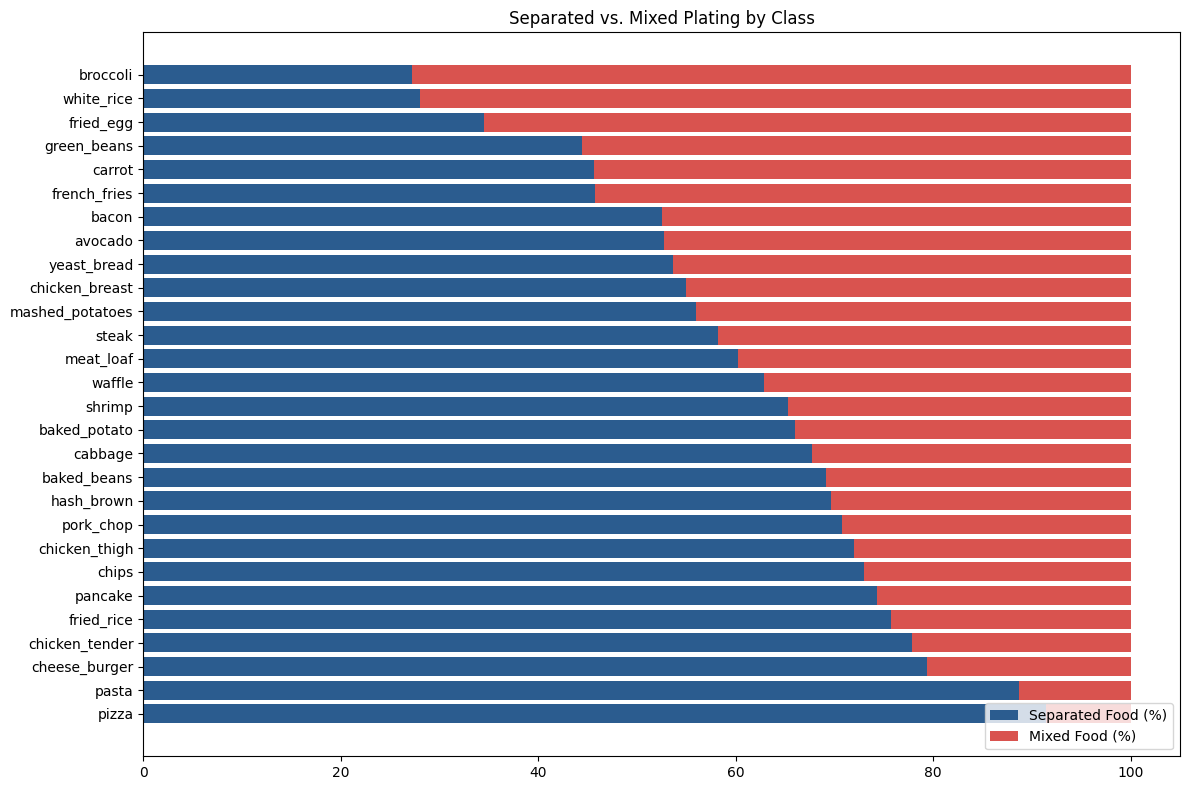


🎉 All EDA reports and plots are successfully saved to: /content/drive/MyDrive/EDA_Outputs


In [ ]:
from google.colab import drive
import os
import hashlib
from pathlib import Path
from collections import defaultdict
import concurrent.futures
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

# ================= 1. VERIFY MOUNT & SET PATHS =================
drive.mount('/content/drive')

# REPLACE THIS with the exact path printed from Step 1:
# Example: Path('/content/drive/MyDrive/vfn_1_0') or Path('/content/drive/MyDrive/Colab Notebooks/vfn_1_0')
DATA_DIR = Path('/content/drive/MyDrive/vfn_1_0')

IMAGES_BASE = DATA_DIR / 'Images'
META_ANN_FILE = DATA_DIR / 'Meta' / 'annotations.txt'

# Use os.makedirs with exist_ok=True to ensure Drive creates the folder
OUTPUT_DIR = Path('/content/drive/MyDrive/EDA_Outputs')
os.makedirs(str(OUTPUT_DIR), exist_ok=True)

# 28 Target Classes
TARGET_CLASSES = {
    4: "avocado", 5: "bacon", 7: "baked_beans", 8: "baked_potato",
    16: "broccoli", 20: "cabbage", 23: "carrot", 24: "cheese_burger",
    26: "chicken_breast", 28: "chicken_tender", 29: "chicken_thigh",
    31: "chips", 41: "french_fries", 43: "fried_egg", 44: "fried_rice",
    46: "green_beans", 48: "hash_brown", 53: "mashed_potatoes",
    54: "meat_loaf", 58: "pancake", 59: "pasta", 60: "pizza",
    61: "pork_chop", 65: "shrimp", 67: "steak", 77: "waffle",
    78: "white_rice", 80: "yeast_bread"
}

# ================= 2. SCANNING & VALIDATION =================
print(f"Scanning from: {IMAGES_BASE}")
if not IMAGES_BASE.exists():
    raise FileNotFoundError(
        f"Folder '{IMAGES_BASE}' does not exist! Please check the folder path in Google Drive."
    )

image_tasks = []
for cid, cname in TARGET_CLASSES.items():
    folder = IMAGES_BASE / str(cid)
    if not folder.exists():
        continue
    for p in folder.glob("*.*"):
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            image_tasks.append((p, cid, cname))

print(f"-> Successfully found {len(image_tasks)} images across the 28 folders!")

if len(image_tasks) == 0:
    raise ValueError(
        f"No images found inside {IMAGES_BASE}. Please check if the subfolders (4, 5, 7, etc.) exist."
    )

# Load annotations if available
ann_by_img = defaultdict(list)
if META_ANN_FILE.exists():
    with open(META_ANN_FILE, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 6:
                ann_by_img[parts[0]].append(int(parts[5]))

# ================= 3. IMAGE METRICS EXTRACTION =================
def compute_md5(filepath):
    h = hashlib.md5()
    with open(filepath, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

def analyze_image(item):
    p, cid, cname = item
    fname = p.name
    fsize_kb = p.stat().st_size / 1024.0

    try:
        with Image.open(p) as img:
            img.verify()
        with Image.open(p) as img:
            w_pil, h_pil = img.size
            img_format = img.format
            img_mode = img.mode
    except Exception:
        return {"filename": fname, "is_corrupt": True}

    try:
        md5_str = compute_md5(p)
        cv_img = cv2.imread(str(p))
        if cv_img is None:
            return {"filename": fname, "is_corrupt": True}

        h, w, channels = cv_img.shape
        gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)

        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        brightness = float(gray.mean())
        contrast = float(gray.std())

        mean_b, mean_g, mean_r = [float(x) for x in cv_img.mean(axis=(0, 1))]
        std_b, std_g, std_r = [float(x) for x in cv_img.std(axis=(0, 1))]

        boxes = ann_by_img.get(fname, [])
        distinct_cats = len(set(boxes))

        return {
            "filename": fname, "path": str(p), "vfn_id": cid, "class_name": cname,
            "is_corrupt": False, "format": img_format, "mode": img_mode, "channels": channels,
            "width": w, "height": h, "megapixels": round((w * h) / 1e6, 4),
            "aspect_ratio": round(w / h, 3) if h > 0 else 0,
            "file_size_kb": round(fsize_kb, 2),
            "sharpness": round(sharpness, 2), "brightness": round(brightness, 2), "contrast": round(contrast, 2),
            "mean_r": round(mean_r, 2), "mean_g": round(mean_g, 2), "mean_b": round(mean_b, 2),
            "num_food_items": len(boxes), "distinct_food_categories": distinct_cats,
            "is_mixed_food": distinct_cats > 1,
            "md5": md5_str
        }
    except Exception:
        return {"filename": fname, "is_corrupt": True}

print("Processing images (using 8 parallel threads for Colab)...")
records = []
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as ex:
    for r in ex.map(analyze_image, image_tasks):
        if r is not None:
            records.append(r)

df = pd.DataFrame(records)
valid_df = df[~df["is_corrupt"]].copy()

# Save main metrics CSV to Drive
csv_out = OUTPUT_DIR / "pure_eda_images.csv"
df.to_csv(csv_out, index=False)
print(f"✅ Saved image metrics to: {csv_out}")

# ================= 4. SUMMARIES & PLOTS =================
# Class summary
class_rows = []
for cid, cname in TARGET_CLASSES.items():
    sub = valid_df[valid_df["vfn_id"] == cid]
    n = len(sub)
    if n == 0: continue
    class_rows.append({
        "vfn_id": cid, "class_name": cname, "image_count": n,
        "class_pct": round(n / len(valid_df) * 100, 2),
        "avg_width": round(sub["width"].mean(), 1), "avg_height": round(sub["height"].mean(), 1),
        "median_aspect_ratio": round(sub["aspect_ratio"].median(), 2),
        "avg_sharpness": round(sub["sharpness"].mean(), 1), "avg_brightness": round(sub["brightness"].mean(), 1),
        "blurry_count (<50)": (sub["sharpness"] < 50).sum()
    })

summary_df = pd.DataFrame(class_rows).sort_values(by="image_count", ascending=False)
summary_df.to_csv(OUTPUT_DIR / "pure_eda_class_summary.csv", index=False)

# Separated vs Mixed summary
mix_stats = []
for cid, sub in valid_df.groupby(["vfn_id", "class_name"]):
    tot = len(sub)
    sep_cnt = (sub["distinct_food_categories"] == 1).sum()
    mix_cnt = (sub["distinct_food_categories"] > 1).sum()
    mix_stats.append({
        "class_name": cid[1], "total_images": tot,
        "separated_food_count": sep_cnt, "mixed_food_count": mix_cnt,
        "separated_pct": round(sep_cnt / tot * 100, 1),
        "mixed_pct": round(mix_cnt / tot * 100, 1)
    })
mix_df = pd.DataFrame(mix_stats).sort_values(by="mixed_pct", ascending=True)
mix_df.to_csv(OUTPUT_DIR / "mixed_vs_separated_summary.csv", index=False)

# Chart 1: Class Distribution
plt.figure(figsize=(12, 8))
plt.barh(summary_df["class_name"][::-1], summary_df["image_count"][::-1], color="#2b5c8f")
plt.title("Class Frequency (28 Selected Classes)")
plt.xlabel("Image Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pure_eda_1_class_distribution.png", dpi=200)
plt.show()

# Chart 2: Separated vs Mixed Plating
fig, ax = plt.subplots(figsize=(12, 8))
y_p = np.arange(len(mix_df))
ax.barh(y_p, mix_df["separated_pct"], color="#2b5c8f", label="Separated Food (%)")
ax.barh(y_p, mix_df["mixed_pct"], left=mix_df["separated_pct"], color="#d9534f", label="Mixed Food (%)")
ax.set_yticks(y_p)
ax.set_yticklabels(mix_df["class_name"])
ax.set_title("Separated vs. Mixed Plating by Class")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mixed_vs_separated_by_class.png", dpi=200)
plt.show()

print(f"\n🎉 All EDA reports and plots are successfully saved to: {OUTPUT_DIR}")

Total unique mixed-food dishes: 1591
Average kinds of food per mixed dish: 2.34
Median kinds of food per mixed dish:  2.0
Max kinds of food in a single dish:   5

Breakdown by number of distinct food kinds:
  2 kinds of food: 1159 images (72.85%)
  3 kinds of food:  337 images (21.18%)
  4 kinds of food:   82 images ( 5.15%)
  5 kinds of food:   13 images ( 0.82%)

Top 10 most common mixed-food combinations:
kinds
mashed_potatoes, meat_loaf    22
fried_egg, fried_rice         20
blueberries, pancake          18
stew_beef, yeast_bread        15
avocado, chips                15
chips, tomatoes               13
mashed_potatoes, steak        12
baked_potato, pork_chop       12
chicken_thigh, white_rice     12
french_fries, steak           11


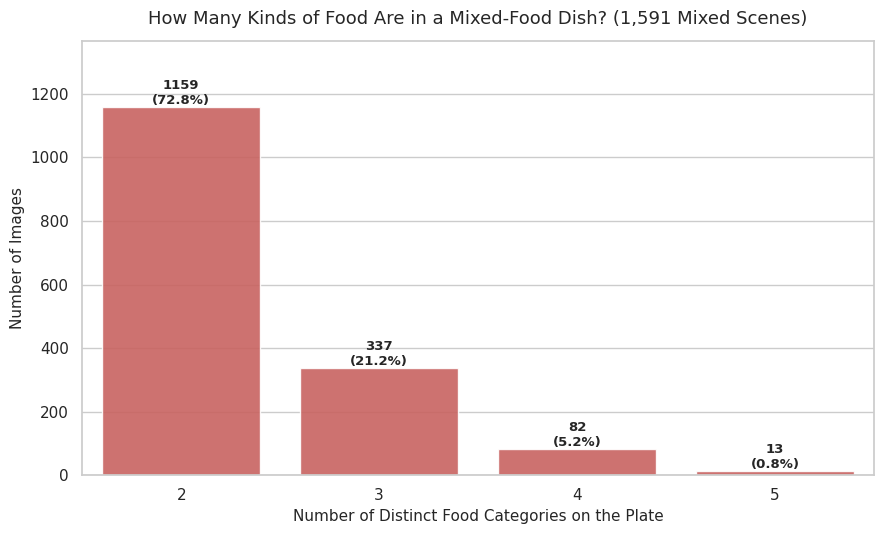


✅ Saved chart to: /content/drive/MyDrive/EDA_Outputs/mixed_food_kind_counts.png
✅ Saved details CSV to: /content/drive/MyDrive/EDA_Outputs/mixed_food_kind_details.csv


In [ ]:
# ==============================================================
# 6. HOW MANY KINDS OF FOOD ARE IN A MIXED-FOOD DISH?
# (Run in sequence after the previous Colab cell)
# ==============================================================

# Load full category name mapping (falls back to TARGET_CLASSES if file not found)
cat_names = dict(TARGET_CLASSES)
cat_file = DATA_DIR / "Meta" / "category_ids.txt"
if cat_file.exists():
    with open(cat_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                cat_names[int(parts[0])] = parts[1]

# Deduplicate to unique scenes and filter to mixed-food dishes (2+ distinct kinds)
unique_scenes = valid_df.drop_duplicates(subset=["filename"]).copy()
mixed_rows = []

for fname in unique_scenes["filename"]:
    cats = ann_by_img.get(fname, [])
    distinct_cats = sorted(set(cats))
    if len(distinct_cats) > 1:
        mixed_rows.append({
            "filename": fname,
            "num_kinds": len(distinct_cats),
            "num_total_items": len(cats),
            "kinds": ", ".join(cat_names.get(c, str(c)) for c in distinct_cats)
        })

mixed_df = pd.DataFrame(mixed_rows)

# 1. Print Summary Statistics
print(f"Total unique mixed-food dishes: {len(mixed_df)}")
print(f"Average kinds of food per mixed dish: {mixed_df['num_kinds'].mean():.2f}")
print(f"Median kinds of food per mixed dish:  {mixed_df['num_kinds'].median():.1f}")
print(f"Max kinds of food in a single dish:   {mixed_df['num_kinds'].max()}\n")

print("Breakdown by number of distinct food kinds:")
kind_dist = mixed_df["num_kinds"].value_counts().sort_index()
for k, count in kind_dist.items():
    pct = count / len(mixed_df) * 100
    print(f"  {k} kinds of food: {count:4d} images ({pct:5.2f}%)")

print("\nTop 10 most common mixed-food combinations:")
print(mixed_df["kinds"].value_counts().head(10).to_string())

# Save detailed mixed-dish table to Drive
mixed_df.to_csv(OUTPUT_DIR / "mixed_food_kind_details.csv", index=False)

# 2. Plot Distribution Chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=kind_dist.index, y=kind_dist.values, ax=ax, color="#d9534f", alpha=0.9)

ax.set_title(f"How Many Kinds of Food Are in a Mixed-Food Dish? ({len(mixed_df):,} Mixed Scenes)", fontsize=13, pad=12)
ax.set_xlabel("Number of Distinct Food Categories on the Plate", fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)

for p in ax.patches:
    h = p.get_height()
    ax.annotate(
        f"{int(h)}\n({h / len(mixed_df) * 100:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, h),
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

ax.set_ylim(0, kind_dist.max() * 1.18)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mixed_food_kind_counts.png", dpi=200)
plt.show()

print(f"\n✅ Saved chart to: {OUTPUT_DIR / 'mixed_food_kind_counts.png'}")
print(f"✅ Saved details CSV to: {OUTPUT_DIR / 'mixed_food_kind_details.csv'}")

Top 10 Foods Appearing Most Frequently in Mixed-Food Dishes (out of 1,591 mixed dishes):

      food_name  mixed_dish_appearances  pct_of_mixed_dishes
     white_rice                     177                11.13
          steak                     166                10.43
    yeast_bread                     137                 8.61
       broccoli                     134                 8.42
      fried_egg                     133                 8.36
mashed_potatoes                     133                 8.36
          chips                     123                 7.73
   french_fries                     123                 7.73
   baked_potato                     121                 7.61
 chicken_breast                     118                 7.42


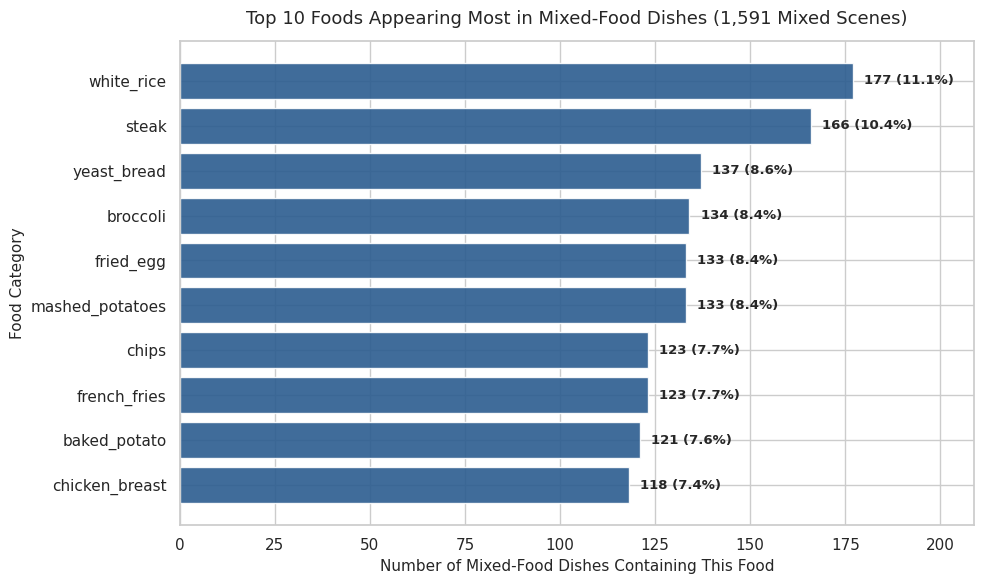


✅ Saved chart to: /content/drive/MyDrive/EDA_Outputs/top_10_foods_in_mixed_dishes.png
✅ Saved full ranking CSV to: /content/drive/MyDrive/EDA_Outputs/top_foods_in_mixed_dishes.csv


In [ ]:
# ==============================================================
# 7. TOP 10 FOODS APPEARING THE MOST IN MIXED-FOOD DISHES
# (Run in sequence after the previous Colab cell)
# ==============================================================
from collections import Counter

# Count in how many unique mixed-food dishes each food category appears
food_in_mixed_counter = Counter()

for fname in mixed_df["filename"]:
    distinct_cats = set(ann_by_img.get(fname, []))
    for cid in distinct_cats:
        food_name = cat_names.get(cid, str(cid))
        food_in_mixed_counter[food_name] += 1

# Build full ranking DataFrame
top_mixed_df = pd.DataFrame(
    food_in_mixed_counter.most_common(),
    columns=["food_name", "mixed_dish_appearances"]
)
top_mixed_df["pct_of_mixed_dishes"] = (
    top_mixed_df["mixed_dish_appearances"] / len(mixed_df) * 100
).round(2)

# Save full table to Drive
top_mixed_df.to_csv(OUTPUT_DIR / "top_foods_in_mixed_dishes.csv", index=False)

# Print Top 10
top_10 = top_mixed_df.head(10)
print(f"Top 10 Foods Appearing Most Frequently in Mixed-Food Dishes (out of {len(mixed_df):,} mixed dishes):\n")
print(top_10.to_string(index=False))

# Plot Horizontal Bar Chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = top_10.iloc[::-1]  # Reverse so #1 is at the top

bars = ax.barh(
    plot_data["food_name"],
    plot_data["mixed_dish_appearances"],
    color="#2b5c8f",
    alpha=0.9
)

ax.set_title(f"Top 10 Foods Appearing Most in Mixed-Food Dishes ({len(mixed_df):,} Mixed Scenes)", fontsize=13, pad=12)
ax.set_xlabel("Number of Mixed-Food Dishes Containing This Food", fontsize=11)
ax.set_ylabel("Food Category", fontsize=11)

for bar, count, pct in zip(bars, plot_data["mixed_dish_appearances"], plot_data["pct_of_mixed_dishes"]):
    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({pct:.1f}%)",
        va="center",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_xlim(0, top_10["mixed_dish_appearances"].max() * 1.18)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_10_foods_in_mixed_dishes.png", dpi=200)
plt.show()

print(f"\n✅ Saved chart to: {OUTPUT_DIR / 'top_10_foods_in_mixed_dishes.png'}")
print(f"✅ Saved full ranking CSV to: {OUTPUT_DIR / 'top_foods_in_mixed_dishes.csv'}")